 02_visualization_vllm — plots from processed vLLM benchmark outputs

In [82]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)

ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
PROCESSED_DIR = ROOT / "results" / "processed"
FIGURES_DIR = ROOT / "docs" / "figures" / "vllm"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

summary_path = PROCESSED_DIR / "summary_vllm.csv"
samples_path = PROCESSED_DIR / "samples_vllm.csv"
ranking_accuracy_path = PROCESSED_DIR / "ranking_accuracy_vllm.csv"
ranking_efficiency_path = PROCESSED_DIR / "ranking_efficiency_vllm.csv"

summary = pd.read_csv(summary_path)
samples = pd.read_csv(samples_path)
ranking_accuracy = pd.read_csv(ranking_accuracy_path)
ranking_efficiency = pd.read_csv(ranking_efficiency_path)

print("summary:", summary.shape)
print("samples:", samples.shape)
print("ranking_accuracy:", ranking_accuracy.shape)
print("ranking_efficiency:", ranking_efficiency.shape)


summary: (20, 46)
samples: (15500, 41)
ranking_accuracy: (5, 19)
ranking_efficiency: (5, 19)


 Quick inspection

In [83]:
display(summary.head())
display(samples.head())
display(ranking_accuracy.head())


,backend,run_id,dataset,model_alias_dir,source_path,model,repo_id,served_model_id,accuracy,accuracy_sd,ttft,ttft_sd,latency,latency_sd,tps,tps_sd,cpu,cpu_sd,cpu_peak,ram_used_mb_peak,ram,temp_c_avg,temp_c_avg_sd,temp_c_peak,gpu,gpu_sd,gpu_peak,vram,power,power_sd,power_peak,sustained_tps,sustained_tps_sd,sustained_sps,sustained_sps_sd,latency_s,ttft_s,ttft_share_of_latency,tps_per_ram,tps_per_vram,tps_per_watt,sustained_tps_per_vram,accuracy_per_latency,accuracy_per_ram,accuracy_per_vram,accuracy_per_watt
0,vllm,2026-04-07_13-35-14,mmlu,llama3_2_1b,/home/stephane/resource-efficiency-benchmark/r...,llama3_2_1b,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,0.44,0.0,68.2622,0.3665,122.6156,0.7112,18.4056,0.1139,6.0300,0.2637,39.2,9376.24,896.96,68.5707,0.6288,71.500,8.2657,9.4386,22.0,5436.0,58.1622,0.6932,61.44,5.6841,0.0316,5.6841,0.0316,0.122616,0.068262,0.556717,0.020520,0.003386,0.316453,0.001046,0.003588,0.000491,0.000081,0.007565
1,vllm,2026-04-07_13-35-14,hellaswag,llama3_2_1b,/home/stephane/resource-efficiency-benchmark/r...,llama3_2_1b,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,0.24,0.0,68.1985,0.1777,122.4676,0.4120,18.4337,0.0793,5.9284,0.1299,43.4,9272.16,898.32,67.6965,0.2944,68.625,2.5020,6.6964,22.0,5400.0,58.2584,0.0683,60.20,5.6900,0.0191,5.6900,0.0191,0.122468,0.068198,0.556870,0.020520,0.003414,0.316413,0.001054,0.001960,0.000267,0.000044,0.004120
2,vllm,2026-04-07_13-35-14,gsm8k,llama3_2_1b,/home/stephane/resource-efficiency-benchmark/r...,llama3_2_1b,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,0.06,0.0,67.0925,0.2472,138.3586,0.3620,53.9784,0.0768,6.8413,0.0165,23.6,9387.93,899.57,71.7561,0.2473,73.250,44.0157,15.2163,100.0,5370.0,103.1411,1.4601,128.19,23.6684,0.0713,5.2364,0.0158,0.138359,0.067092,0.484917,0.060005,0.010052,0.523345,0.004408,0.000434,0.000067,0.000011,0.000582
3,vllm,2026-04-07_13-35-14,dolly,llama3_2_1b,/home/stephane/resource-efficiency-benchmark/r...,llama3_2_1b,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,NaN,NaN,73.7217,5.8875,471.5200,54.9763,109.4824,4.3976,7.9899,0.2048,22.2,9301.80,899.69,74.9008,0.1878,76.250,66.0237,30.1451,100.0,5158.0,158.7051,4.3896,187.04,83.8610,4.9172,1.9239,0.1934,0.471520,0.073722,0.156349,0.121689,0.021226,0.689848,0.016258,NaN,NaN,NaN,NaN
4,vllm,2026-04-07_13-56-00,mmlu,ministral3_3b_awq,/home/stephane/resource-efficiency-benchmark/r...,ministral3_3b_awq,cyankiwi/Ministral-3-3B-Instruct-2512-AWQ-4bit,cyankiwi/Ministral-3-3B-Instruct-2512-AWQ-4bit,0.64,0.0,82.6019,0.9471,137.8528,0.9156,18.1055,0.0572,5.9592,0.0430,23.9,10783.76,907.05,70.0784,0.2781,73.250,28.6720,8.2209,100.0,5396.0,69.6547,1.8607,102.96,5.2170,0.0256,5.2170,0.0256,0.137853,0.082602,0.599204,0.019961,0.003355,0.259932,0.000967,0.004643,0.000706,0.000119,0.009188


,repo_id,served_model_id,model,dataset_name,run_idx,sample_idx,prompt,question,choices,instruction,context,gold_answer,parsed_prediction,correct,raw_output,output_tokens,ttft_ms,latency_ms,tokens_per_sec,cpu_percent_avg,cpu_percent_peak,ram_used_mb_peak,process_ram_mb_peak,temp_c_avg,temp_c_peak,gpu_percent_avg,gpu_percent_peak,vram_used_mb_peak,power_w_avg,power_w_peak,model_alias_dir,run_id,dataset,source_path,backend,latency_s,ttft_s,ttft_share_of_latency,tokens_per_ram,tokens_per_vram,tokens_per_watt
0,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,llama3_2_1b,mmlu,1,1,"In primates, the location of which of the foll...","In primates, the location of which of the foll...",the feet || the skull || the foramen magnum ||...,NaN,NaN,2.0,C,True,C,1,79.3070,133.0174,18.6184,4.6000,6.3,9370.37,895.34,68.6250,68.625,3.0,3.0,5254.0,47.9233,48.40,llama3_2_1b,2026-04-07_13-35-14,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.133017,0.079307,0.596215,0.020795,0.003544,0.388504
1,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,llama3_2_1b,mmlu,1,2,In the comic strip 'Peanuts' what is Schroeder...,In the comic strip 'Peanuts' what is Schroeder...,Dancing || playing football || playing the pia...,NaN,NaN,2.0,C,True,C,1,67.7943,122.0332,18.4369,6.7000,7.3,9375.46,895.34,68.6250,68.625,3.0,3.0,5254.0,49.9367,50.54,llama3_2_1b,2026-04-07_13-35-14,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.122033,0.067794,0.555540,0.020592,0.003509,0.369205
2,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,llama3_2_1b,mmlu,1,3,The Yang-shao culture gave way to the Lung-Sha...,The Yang-shao culture gave way to the Lung-Sha...,"6,000 B.P. || 5,000 B.P. || 4,000 B.P. || 3,00...",NaN,NaN,1.0,C,False,C,1,67.4295,122.5596,18.1389,5.6000,7.3,9376.24,895.34,68.5833,68.625,3.0,3.0,5254.0,51.2400,52.44,llama3_2_1b,2026-04-07_13-35-14,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.122560,0.067430,0.550177,0.020259,0.003452,0.353999
3,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,llama3_2_1b,mmlu,1,4,At which of the following locations does bile ...,At which of the following locations does bile ...,Gastroesophageal sphincter || Duodenum || Ileo...,NaN,NaN,1.0,C,False,C,1,66.5789,121.0383,18.3623,6.0000,7.3,9353.32,895.34,68.5833,68.625,3.0,3.0,5254.0,52.9467,53.94,llama3_2_1b,2026-04-07_13-35-14,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.121038,0.066579,0.550065,0.020509,0.003495,0.346807
4,unsloth/Llama-3.2-1B-Instruct,unsloth/Llama-3.2-1B-Instruct,llama3_2_1b,mmlu,1,5,"Let A be a finite set with m elements, and let...","Let A be a finite set with m elements, and let...",n^m || n!/(n - m)! || n! || n!/(m!(n - m)!),NaN,NaN,0.0,C,False,C,1,67.9756,122.0342,18.4985,5.5667,7.3,9364.48,895.34,68.6667,68.750,3.0,3.0,5254.0,54.7267,55.12,llama3_2_1b,2026-04-07_13-35-14,mmlu,/home/stephane/resource-efficiency-benchmark/r...,vllm,0.122034,0.067976,0.557021,0.020661,0.003521,0.338016


,backend,model,n_runs,n_datasets,avg_accuracy,avg_ttft_ms,avg_latency_ms,avg_tps,avg_sustained_tps,avg_cpu,avg_ram_mb,avg_gpu,avg_vram_mb,avg_power_w,avg_tps_per_vram,avg_tps_per_watt,avg_accuracy_per_latency,avg_accuracy_per_vram,avg_accuracy_per_watt
0,vllm,qwen3_4b_awq,1,3,0.478000,99.074733,182.429967,39.535233,15.010633,6.025633,848.470000,32.574467,5283.000000,98.690900,0.007520,0.351571,0.002791,0.000090,0.005783
1,vllm,phi4mini_gptq_4bit,1,3,0.420000,72.685767,128.036433,39.943633,12.119133,6.530667,1069.146667,14.282533,5929.333333,69.607567,0.006734,0.566577,0.003269,0.000071,0.005978
2,vllm,ministral3_3b_awq,1,3,0.380000,82.970433,148.970300,33.962533,13.812333,6.365133,908.360000,34.762467,5231.666667,87.474600,0.006544,0.351647,0.002648,0.000072,0.005291
3,vllm,qwen2_5_1_5b,1,3,0.266667,73.553633,137.434067,26.539100,10.924767,6.679633,821.740000,19.106767,5408.333333,74.374267,0.004908,0.341456,0.002061,0.000049,0.004319
4,vllm,llama3_2_1b,1,3,0.246667,67.851067,127.813933,30.272567,11.680833,6.266567,898.283333,18.261133,5402.000000,73.187233,0.005617,0.385404,0.001994,0.000046,0.004089


 Split scored / dolly

In [84]:
scored = summary[summary["dataset"].isin(["mmlu", "hellaswag", "gsm8k"])].copy()
dolly = summary[summary["dataset"] == "dolly"].copy()

print("scored:", scored.shape)
print("dolly:", dolly.shape)


scored: (15, 46)
dolly: (5, 46)


 Average accuracy by model

/tmp/ipykernel_85248/2167707862.py:13: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


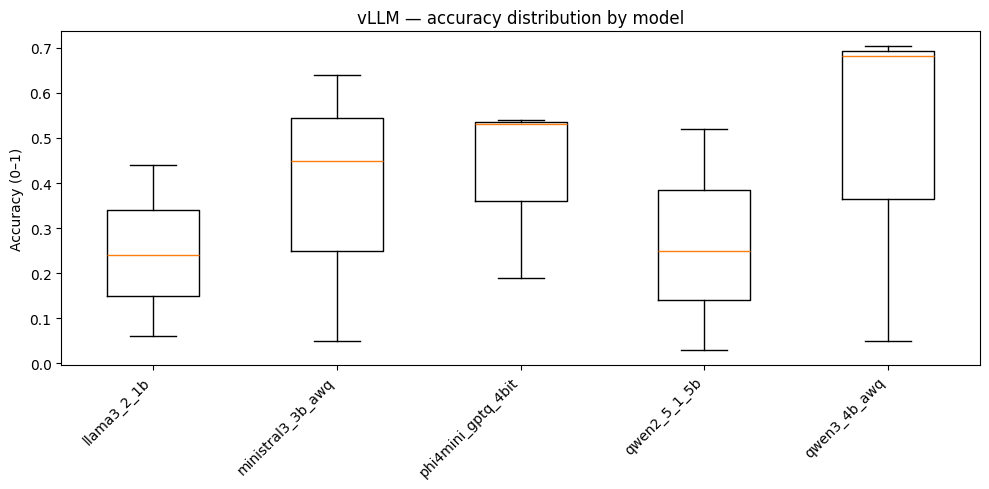

In [85]:

if "accuracy" in scored.columns:
    data = []
    labels = []

    for model_name in sorted(scored["model"].dropna().unique()):
        sub = scored[scored["model"] == model_name]["accuracy"].dropna()

        if len(sub) > 0:
            data.append(sub.values)
            labels.append(model_name)

    plt.figure(figsize=(10, 5))
    plt.boxplot(data, labels=labels, showfliers=True)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Accuracy (0–1)")
    plt.title("vLLM — accuracy distribution by model")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "box_accuracy_by_model.png", dpi=200)
    plt.show()


The figure shows the distribution of accuracy across models for all datasets using the vLLM backend. qwen3_4b_awq has the highest median accuracy, with values concentrated toward the upper end of the range. phi4mini_gguf_4bit and ministral3_3b_awq follow, with comparable medians but wider spreads, indicating greater variability across runs or datasets. The distributions for qwen2.5_1.5b and llama3.2_1b are centered at lower accuracy levels and exhibit more limited upper ranges. Differences in spread across models suggest varying sensitivity to evaluation conditions, while overall trends are consistent with differences in model size and configuration.

 Average latency by model

/tmp/ipykernel_85248/902186600.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


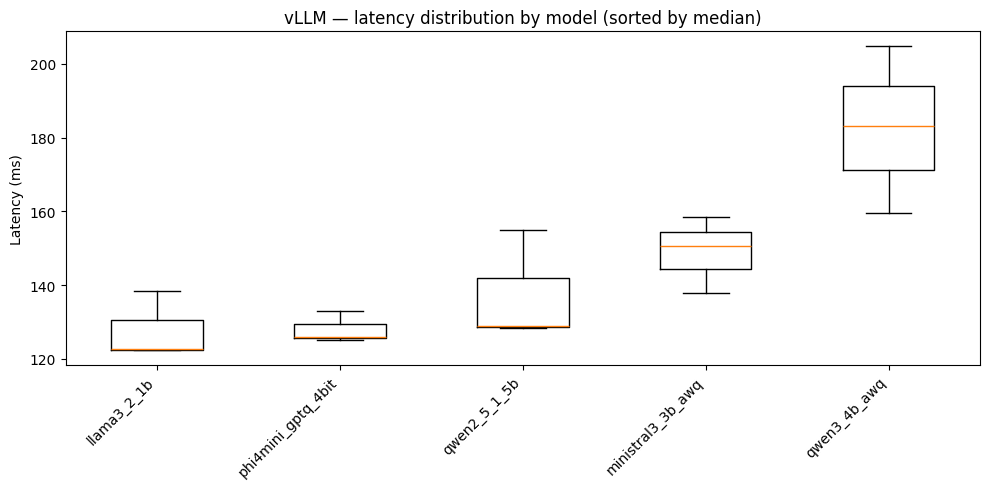

In [86]:

scored = summary[summary["dataset"].isin(["mmlu", "hellaswag", "gsm8k"])].copy()

# resolve latency column safely
latency_col = next(
    (c for c in ["latency_ms", "latency", "end_to_end_latency_ms"] if c in scored.columns),
    None
)

if latency_col is None:
    raise KeyError(f"No latency column found. Available: {scored.columns.tolist()}")

# build grouped data
grouped = [
    (model, scored[scored["model"] == model][latency_col].dropna())
    for model in scored["model"].dropna().unique()
]

grouped = [(m, g) for m, g in grouped if len(g) > 0]

# sort by median latency (fastest first)
grouped.sort(key=lambda x: x[1].median())

labels = [m for m, _ in grouped]
data = [g.values for _, g in grouped]

# plot
plt.figure(figsize=(10, 5))
plt.boxplot(data, labels=labels, showfliers=True)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Latency (ms)")
plt.title("vLLM — latency distribution by model (sorted by median)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "box_latency_by_model_sorted.png", dpi=200)
plt.show()


The figure shows the distribution of end-to-end latency across models for all datasets using the vLLM backend. 

**llama3.2_1b** and **phi4mini_gguf_4bit** exhibit the lowest median latencies, with relatively compact distributions, indicating more consistent response times. **qwen2.5_1.5b** follows with a slightly higher median and increased variability. **ministral3_3b_awq** shows a further shift toward higher latency values, with a moderate spread. **qwen3_4b_awq** has the highest median latency and the widest distribution among the models, indicating both slower and more variable response times. Overall, latency increases across the set of models, with differences in spread suggesting varying degrees of stability in inference time.


 Throughput by model

 GPU utilization by model

/tmp/ipykernel_85248/3259301143.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


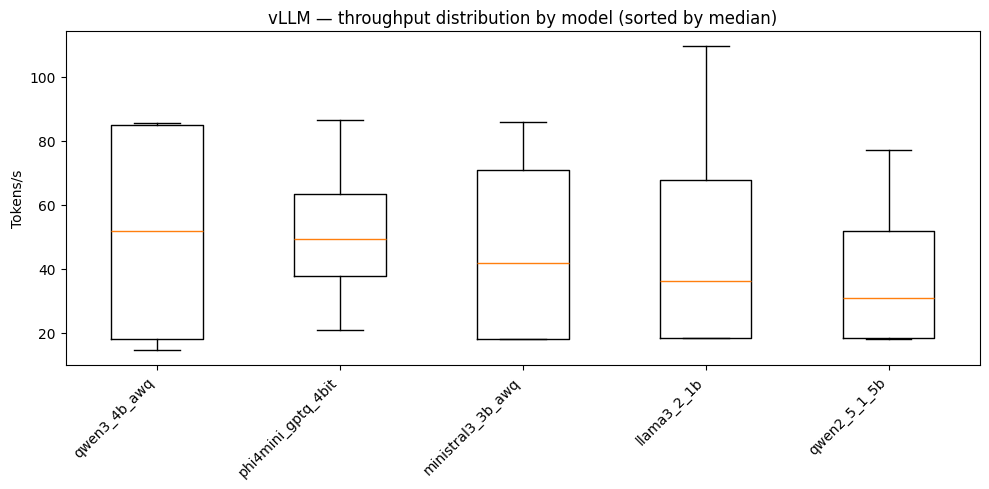

In [87]:

if "summary" not in globals():
    raise RuntimeError("summary DataFrame is not defined")

# resolve column safely
tps_col = next(
    (c for c in ["tps", "tokens_per_sec"] if c in summary.columns),
    None
)

if tps_col is None:
    raise KeyError(f"No throughput column found. Available: {summary.columns.tolist()}")

# build grouped data
grouped = [
    (model, summary[summary["model"] == model][tps_col].dropna())
    for model in summary["model"].dropna().unique()
]

grouped = [(m, g) for m, g in grouped if len(g) > 0]

# sort by median throughput (descending = fastest first)
grouped.sort(key=lambda x: x[1].median(), reverse=True)

labels = [m for m, _ in grouped]
data = [g.values for _, g in grouped]

# plot
plt.figure(figsize=(10, 5))
plt.boxplot(data, labels=labels, showfliers=True)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Tokens/s")
plt.title("vLLM — throughput distribution by model (sorted by median)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "box_throughput_by_model.png", dpi=200)
plt.show()



The figure shows the distribution of token generation throughput across models for all datasets under the vLLM backend. **qwen3_4b_awq** exhibits the highest median throughput, although its distribution is relatively wide, indicating variability in performance across samples. **phi4mini_gguf_4bit** follows with a slightly lower median but a more concentrated distribution. **ministral3_3b_awq** and **llama3.2_1b** show intermediate throughput levels with broader spreads, suggesting greater variability. **qwen2.5_1.5b** has the lowest median throughput among the models, with a distribution skewed toward lower values. Overall, throughput varies substantially across models, both in central tendency and dispersion.


/tmp/ipykernel_85248/1061555978.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


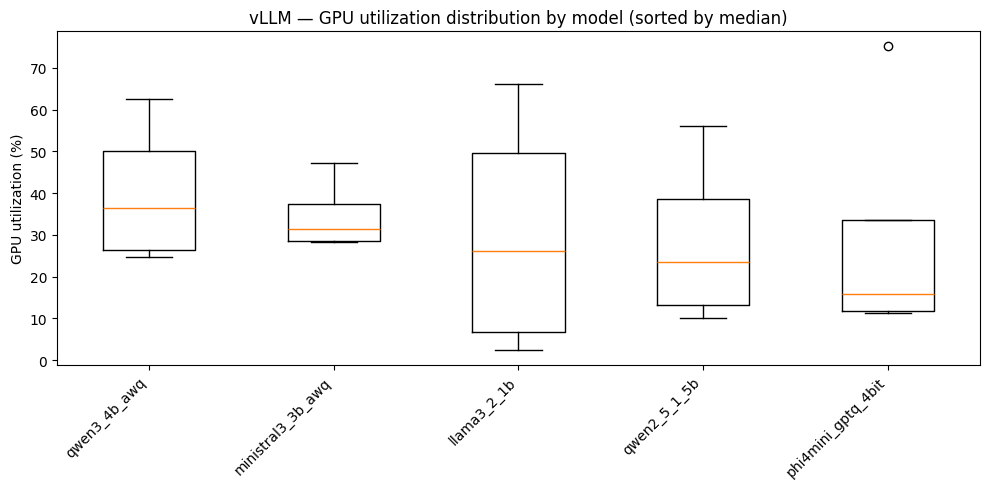

In [ ]:
# GPU utilization boxplot by model

if "summary" not in globals():
    raise RuntimeError("summary DataFrame is not defined")

gpu_col = next(
    (c for c in ["gpu", "gpu_percent_avg", "gpu_util_percent_avg"] if c in summary.columns),
    None
)

if gpu_col is None:
    raise KeyError(f"No GPU column found. Available: {summary.columns.tolist()}")

grouped = [
    (model, summary[summary["model"] == model][gpu_col].dropna())
    for model in summary["model"].dropna().unique()
]

grouped = [(m, g) for m, g in grouped if len(g) > 0]
grouped.sort(key=lambda x: x[1].median(), reverse=True)

labels = [m for m, _ in grouped]
data = [g.values for _, g in grouped]

plt.figure(figsize=(10, 5))
plt.boxplot(data, labels=labels, showfliers=True)
plt.xticks(rotation=45, ha="right")
plt.ylabel("GPU utilization (%)")
plt.title("vLLM — GPU utilization distribution by model (sorted by median)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "box_gpu_by_model.png", dpi=200)
plt.show()



The figure shows the distribution of GPU utilization across models under the vLLM backend. **qwen3_4b_awq** exhibits the highest median utilization, with values extending into higher ranges, indicating more sustained GPU usage. **ministral3_3b_awq** follows with a slightly lower median and a comparatively narrower spread. **llama3.2_1b** and **qwen2.5_1.5b** show lower median utilization levels with broader distributions, reflecting more variable GPU usage. **phi4mini_gguf_4bit** has the lowest median utilization, with most values concentrated at the lower end, although a higher outlier is present. Overall, GPU utilization varies across models in both central tendency and dispersion, suggesting differences in how consistently each model engages available GPU resources.


 VRAM usage by model

/tmp/ipykernel_85248/2113569670.py:27: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


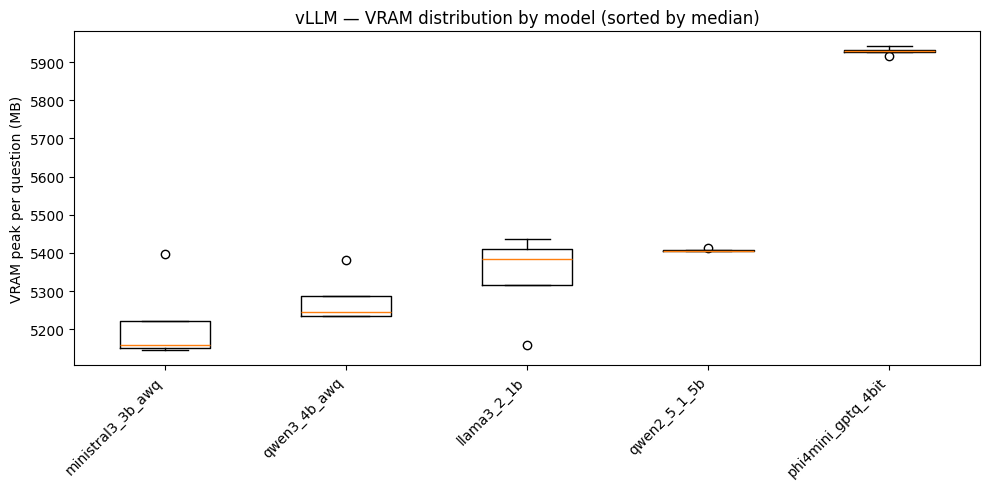

In [89]:
# %%
# VRAM boxplot by model

if "summary" not in globals():
    raise RuntimeError("summary DataFrame is not defined")

vram_col = next(
    (c for c in ["vram", "vram_mb_peak", "vram_used_mb_peak"] if c in summary.columns),
    None
)

if vram_col is None:
    raise KeyError(f"No VRAM column found. Available: {summary.columns.tolist()}")

grouped = [
    (model, summary[summary["model"] == model][vram_col].dropna())
    for model in summary["model"].dropna().unique()
]

grouped = [(m, g) for m, g in grouped if len(g) > 0]
grouped.sort(key=lambda x: x[1].median())

labels = [m for m, _ in grouped]
data = [g.values for _, g in grouped]

plt.figure(figsize=(10, 5))
plt.boxplot(data, labels=labels, showfliers=True)
plt.xticks(rotation=45, ha="right")
plt.ylabel("VRAM peak per question (MB)")
plt.title("vLLM — VRAM distribution by model (sorted by median)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "box_vram_by_model.png", dpi=200)
plt.show()


The figure shows the distribution of VRAM usage per request across models under the vLLM backend. ministral3_3b_awq and qwen3_4b_awq exhibit the lowest median VRAM usage, with relatively narrow distributions. llama3.2_1b and qwen2.5_1.5b show higher median values, with llama3.2_1b displaying a wider spread, indicating greater variability across samples. phi4mini_gguf_4bit has the highest VRAM usage among the models, with values concentrated in a narrow range at the upper end. Overall, VRAM usage differs across models in both level and variability, with some models showing more consistent memory consumption than others.

 Power draw by model

/tmp/ipykernel_85248/3613344382.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


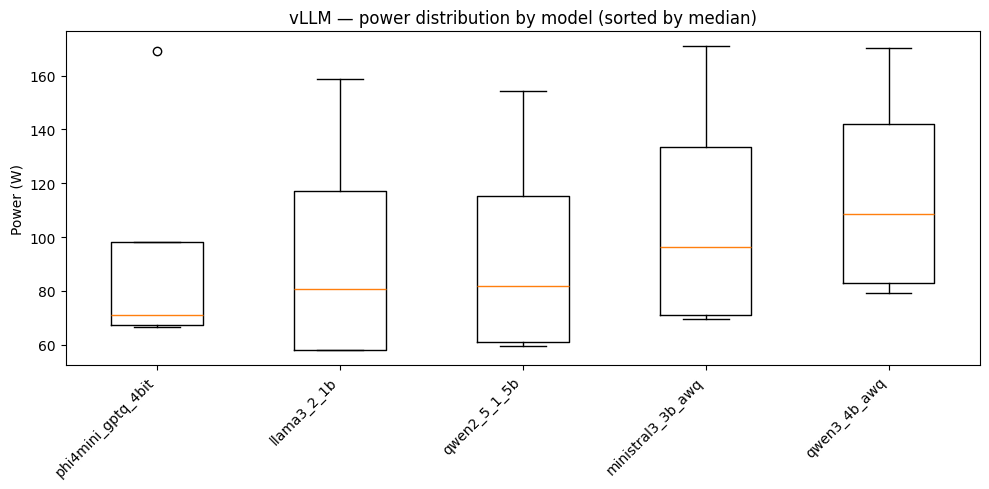

In [90]:

if "summary" not in globals():
    raise RuntimeError("summary DataFrame is not defined")

power_col = next(
    (c for c in ["power", "power_w_avg", "power_w"] if c in summary.columns),
    None
)

if power_col is None:
    raise KeyError(f"No power column found. Available: {summary.columns.tolist()}")

grouped = [
    (model, summary[summary["model"] == model][power_col].dropna())
    for model in summary["model"].dropna().unique()
]

grouped = [(m, g) for m, g in grouped if len(g) > 0]

# lower is better → sort ascending
grouped.sort(key=lambda x: x[1].median())

labels = [m for m, _ in grouped]
data = [g.values for _, g in grouped]

plt.figure(figsize=(10, 5))
plt.boxplot(data, labels=labels, showfliers=True)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Power (W)")
plt.title("vLLM — power distribution by model (sorted by median)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "box_power_by_model.png", dpi=200)
plt.show()


The figure shows the distribution of power consumption across models under the vLLM backend. **phi4mini_gguf_4bit** has the lowest median power usage, with most values concentrated in the lower range, although a higher outlier is observed. **llama3.2_1b** and **qwen2.5_1.5b** exhibit intermediate median values with moderate variability. **ministral3_3b_awq** shows a higher median power draw and a broader distribution, indicating increased variability. **qwen3_4b_awq** has the highest median power consumption, with values extending into the upper range. Overall, power usage increases across models, with differences in spread reflecting variability in consumption across samples.


## Tokens/sec per watt by model

/tmp/ipykernel_85248/3606149621.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


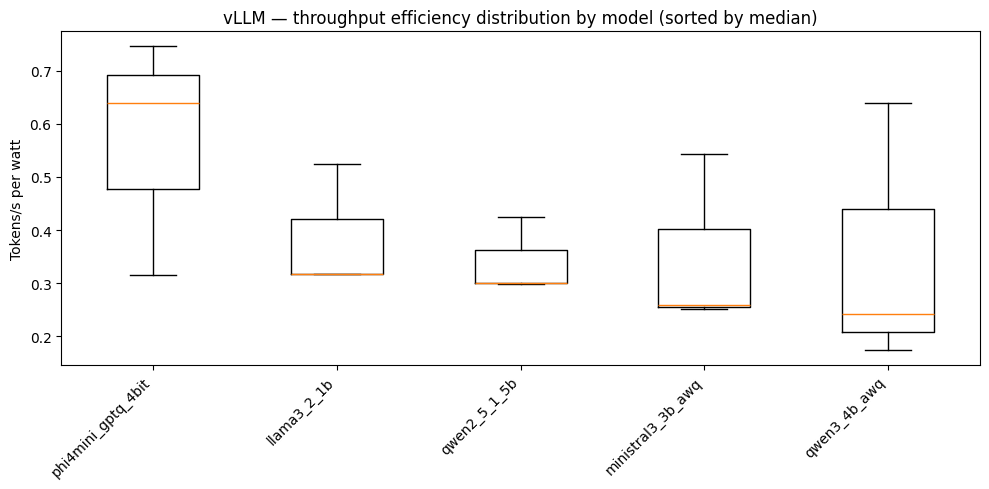

In [ ]:

scored = summary[summary["dataset"].isin(["mmlu", "hellaswag", "gsm8k"])].copy()

eff_col = next(
    (c for c in ["tps_per_watt"] if c in scored.columns),
    None
)

if eff_col is None:
    raise KeyError(f"No efficiency column found. Available: {scored.columns.tolist()}")

grouped = [
    (model, scored[scored["model"] == model][eff_col].dropna())
    for model in scored["model"].dropna().unique()
]

grouped = [(m, g) for m, g in grouped if len(g) > 0]

# higher is better → sort descending
grouped.sort(key=lambda x: x[1].median(), reverse=True)

labels = [m for m, _ in grouped]
data = [g.values for _, g in grouped]

plt.figure(figsize=(10, 5))
plt.boxplot(data, labels=labels, showfliers=True)
plt.xticks(rotation=45, ha="right")
plt.ylabel("Tokens/s per watt")
plt.title("vLLM — throughput efficiency distribution by model (sorted by median)")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "box_tps_per_watt_by_model.png", dpi=200)
plt.show()


 Accuracy vs latency

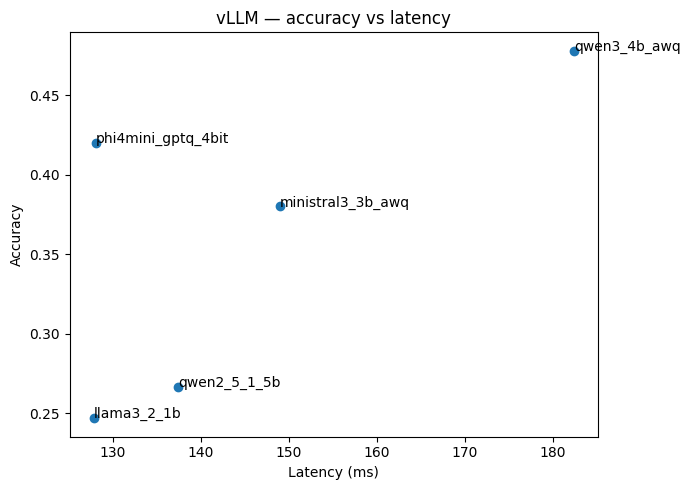

In [92]:
acc_lat = (
    scored.groupby("model", as_index=False)
    .agg({"accuracy": "mean", "latency": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(acc_lat["latency"], acc_lat["accuracy"])

for _, row in acc_lat.iterrows():
    plt.annotate(row["model"], (row["latency"], row["accuracy"]))

plt.xlabel("Latency (ms)")
plt.ylabel("Accuracy")
plt.title("vLLM — accuracy vs latency")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_latency.png", dpi=200)
plt.show()


 Accuracy vs power

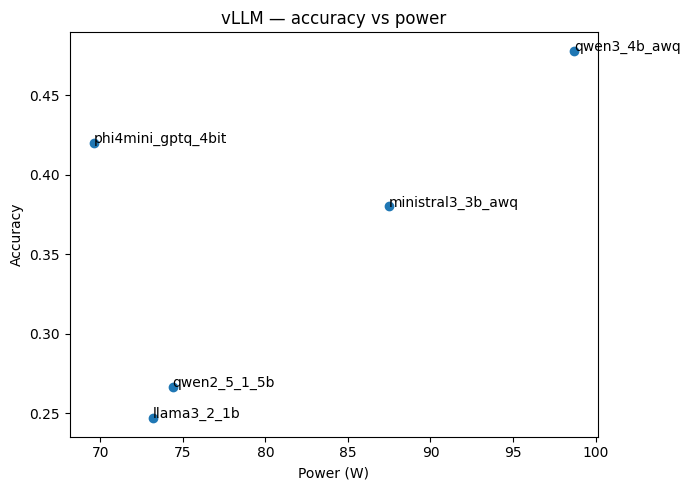

In [93]:
acc_power = (
    scored.groupby("model", as_index=False)
    .agg({"accuracy": "mean", "power": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(acc_power["power"], acc_power["accuracy"])

for _, row in acc_power.iterrows():
    plt.annotate(row["model"], (row["power"], row["accuracy"]))

plt.xlabel("Power (W)")
plt.ylabel("Accuracy")
plt.title("vLLM — accuracy vs power")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_power.png", dpi=200)
plt.show()


 Throughput vs VRAM

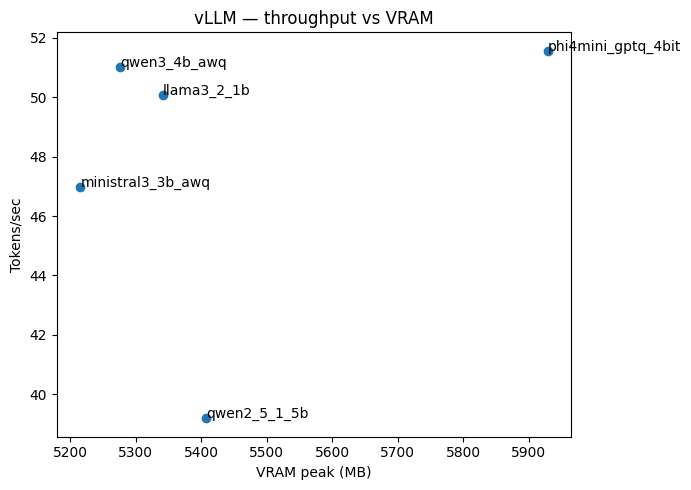

In [94]:
tps_vram = (
    summary.groupby("model", as_index=False)
    .agg({"tps": "mean", "vram": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(tps_vram["vram"], tps_vram["tps"])

for _, row in tps_vram.iterrows():
    plt.annotate(row["model"], (row["vram"], row["tps"]))

plt.xlabel("VRAM peak (MB)")
plt.ylabel("Tokens/sec")
plt.title("vLLM — throughput vs VRAM")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "throughput_vs_vram.png", dpi=200)
plt.show()


 Throughput vs power

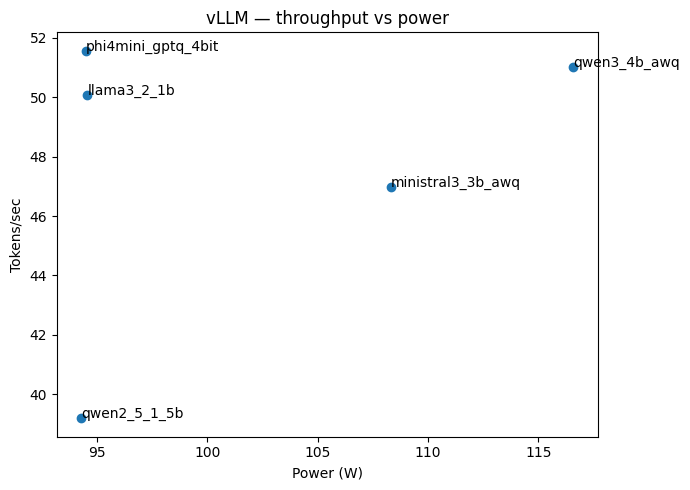

In [95]:
tps_power = (
    summary.groupby("model", as_index=False)
    .agg({"tps": "mean", "power": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(tps_power["power"], tps_power["tps"])

for _, row in tps_power.iterrows():
    plt.annotate(row["model"], (row["power"], row["tps"]))

plt.xlabel("Power (W)")
plt.ylabel("Tokens/sec")
plt.title("vLLM — throughput vs power")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "throughput_vs_power.png", dpi=200)
plt.show()


 Accuracy vs VRAM

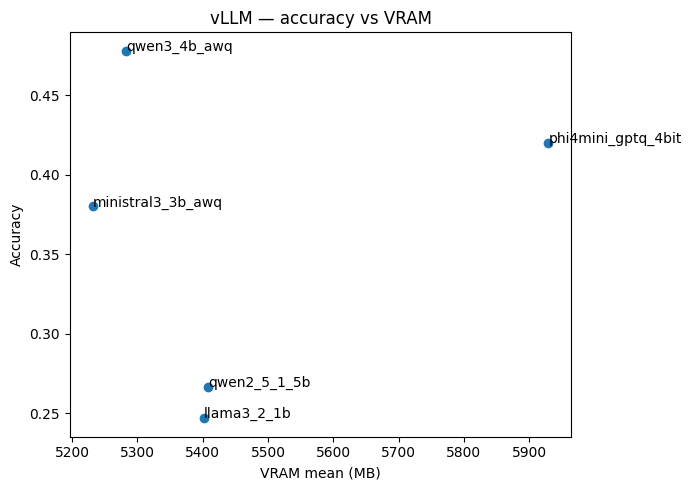

In [96]:
acc_vram = (
    scored.groupby("model", as_index=False)
    .agg({"accuracy": "mean", "vram": "mean"})
)

plt.figure(figsize=(7, 5))
plt.scatter(acc_vram["vram"], acc_vram["accuracy"])

for _, row in acc_vram.iterrows():
    plt.annotate(row["model"], (row["vram"], row["accuracy"]))

plt.xlabel("VRAM mean (MB)")
plt.ylabel("Accuracy")
plt.title("vLLM — accuracy vs VRAM")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "accuracy_vs_vram.png", dpi=200)
plt.show()


 Per-dataset accuracy

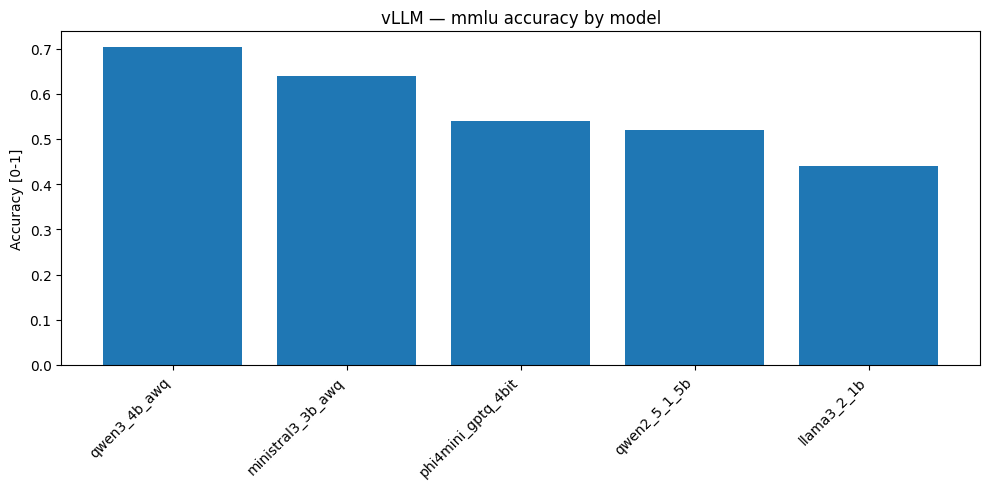

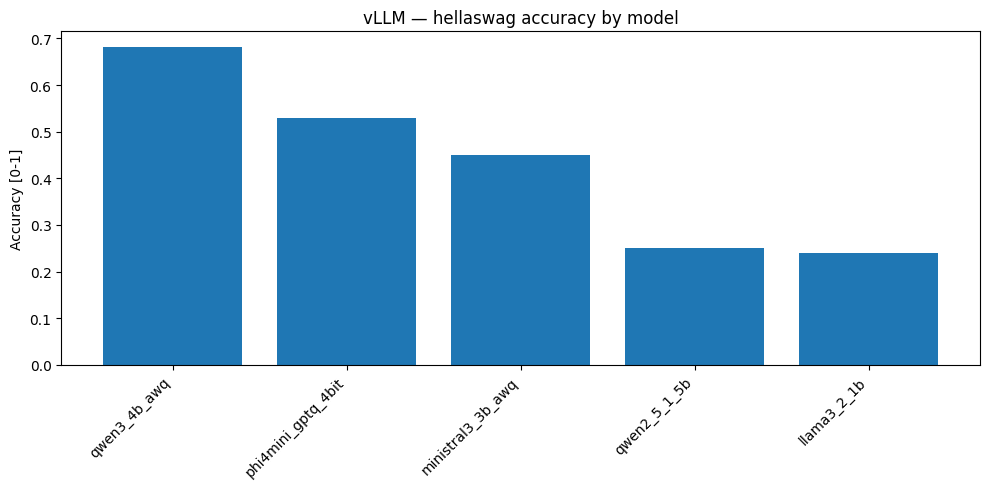

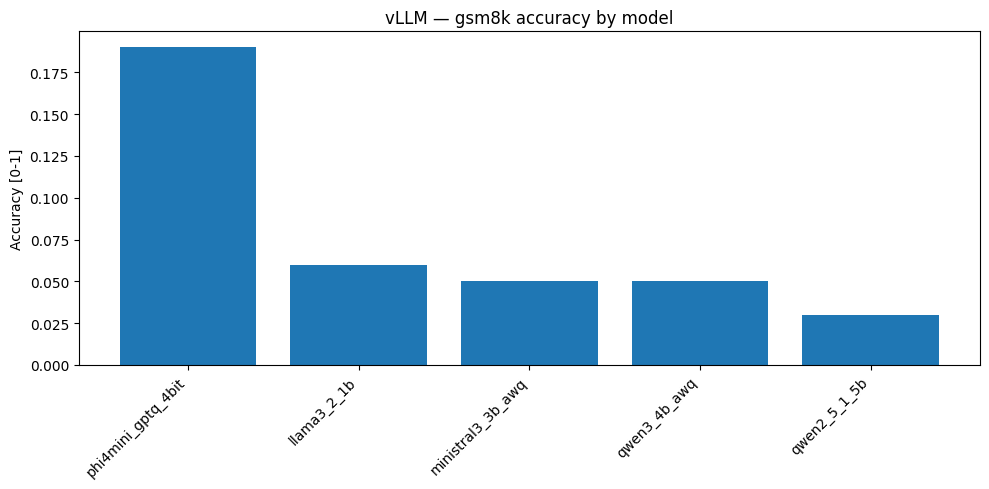

In [97]:

for ds in ["mmlu", "hellaswag", "gsm8k"]:
    sub = (
        scored[scored["dataset"] == ds]
        .groupby("model", as_index=False)["accuracy"]
        .mean()
        .sort_values("accuracy", ascending=False)
    )

    plt.figure(figsize=(10, 5))
    plt.bar(sub["model"], sub["accuracy"])
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Accuracy [0-1]")
    plt.title(f"vLLM — {ds} accuracy by model")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / f"{ds}_accuracy_by_model.png", dpi=200)
    plt.show()

 Per-dataset latency

/tmp/ipykernel_85248/272140189.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


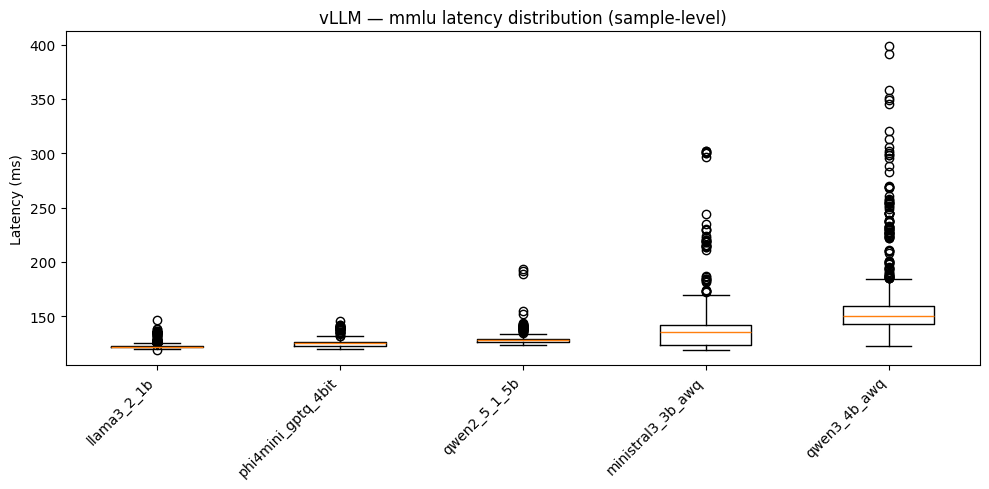

/tmp/ipykernel_85248/272140189.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


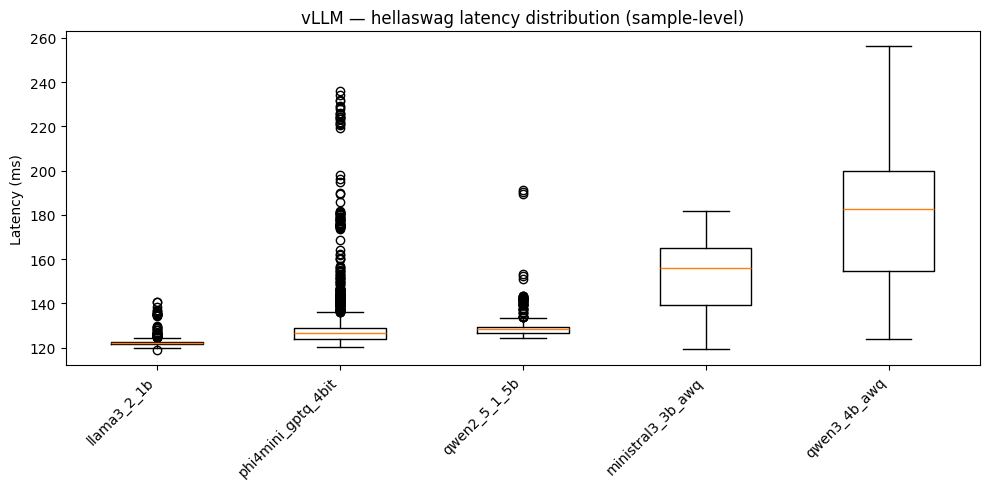

/tmp/ipykernel_85248/272140189.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


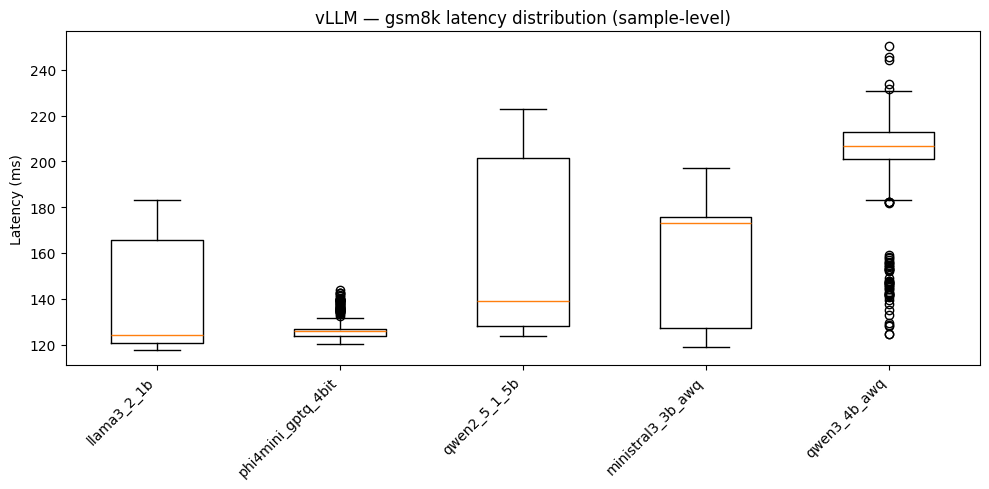

/tmp/ipykernel_85248/272140189.py:25: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


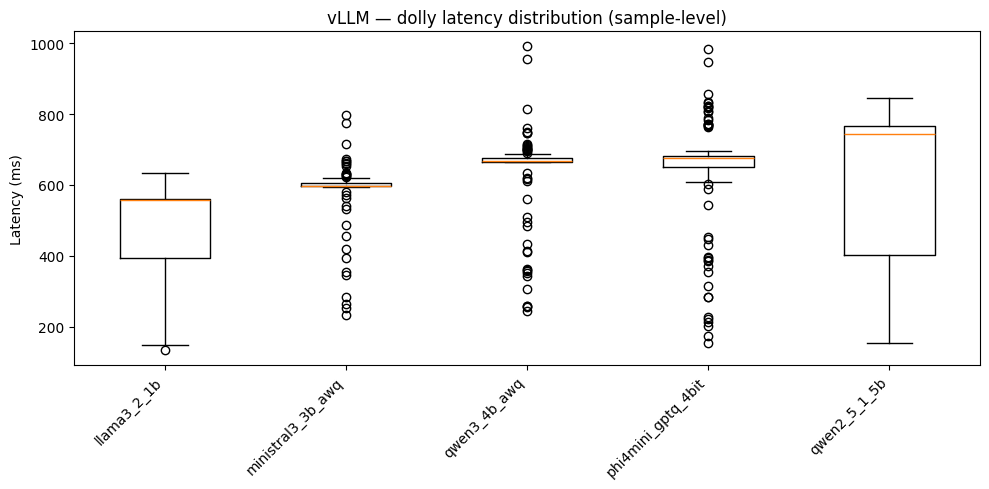

In [ ]:

for ds in ["mmlu", "hellaswag", "gsm8k", "dolly"]:
    sub_df = samples[samples["dataset"] == ds]

    latency_col = next(
        (c for c in ["latency_ms", "latency", "end_to_end_latency_ms"] if c in sub_df.columns),
        None
    )

    if latency_col is None or sub_df.empty:
        continue

    grouped = [
        (model, sub_df[sub_df["model"] == model][latency_col].dropna())
        for model in sub_df["model"].dropna().unique()
    ]

    grouped = [(m, g) for m, g in grouped if len(g) > 0]
    grouped.sort(key=lambda x: x[1].median())

    labels = [m for m, _ in grouped]
    data = [g.values for _, g in grouped]

    plt.figure(figsize=(10, 5))
    plt.boxplot(data, labels=labels, showfliers=True)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Latency (ms)")
    plt.title(f"vLLM — {ds} latency distribution (sample-level)")
    plt.tight_layout()
    plt.show()


 Dolly throughput

/tmp/ipykernel_85248/3250159412.py:38: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data, labels=labels, showfliers=True)


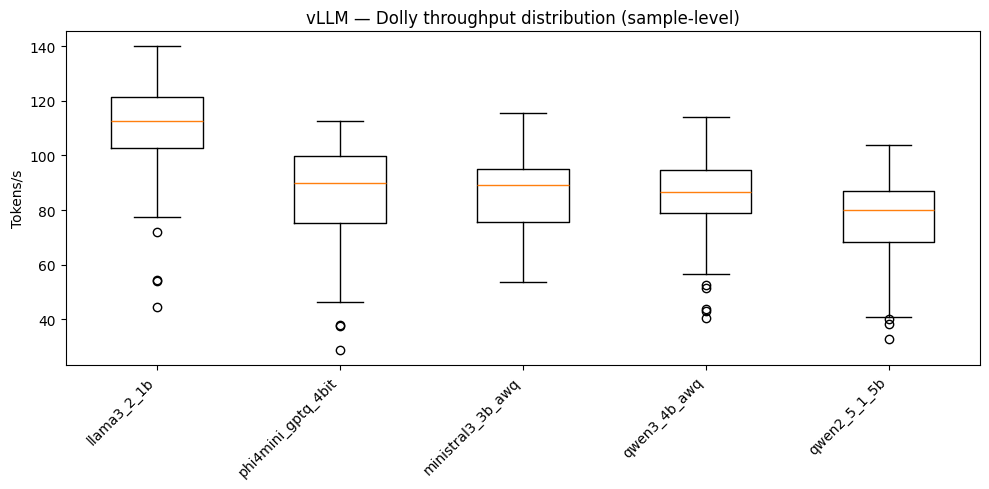

In [99]:
# %%
if "samples" not in globals():
    raise RuntimeError("samples DataFrame is not defined")

dolly = samples[samples["dataset"] == "dolly"].copy()

if not dolly.empty:
    tps_col = next(
        (c for c in ["tokens_per_sec"] if c in dolly.columns),
        None
    )

    model_col = next(
        (c for c in ["model", "model_alias", "model_alias_dir"] if c in dolly.columns),
        None
    )

    if tps_col is None:
        raise KeyError(f"No tokens/sec column found. Available: {dolly.columns.tolist()}")

    if model_col is None:
        raise KeyError(f"No model column found. Available: {dolly.columns.tolist()}")

    grouped = [
        (model, dolly[dolly[model_col] == model][tps_col].dropna())
        for model in dolly[model_col].dropna().unique()
    ]

    grouped = [(m, g) for m, g in grouped if len(g) > 0]

    # higher throughput is better
    grouped.sort(key=lambda x: x[1].median(), reverse=True)

    labels = [m for m, _ in grouped]
    data = [g.values for _, g in grouped]

    plt.figure(figsize=(10, 5))
    plt.boxplot(data, labels=labels, showfliers=True)
    plt.xticks(rotation=45, ha="right")
    plt.ylabel("Tokens/s")
    plt.title("vLLM — Dolly throughput distribution (sample-level)")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "box_dolly_throughput_samples.png", dpi=200)
    plt.show()

 Sample latency distribution by model

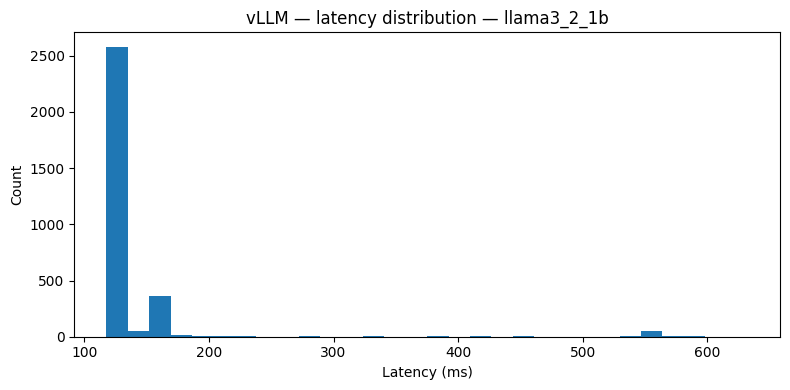

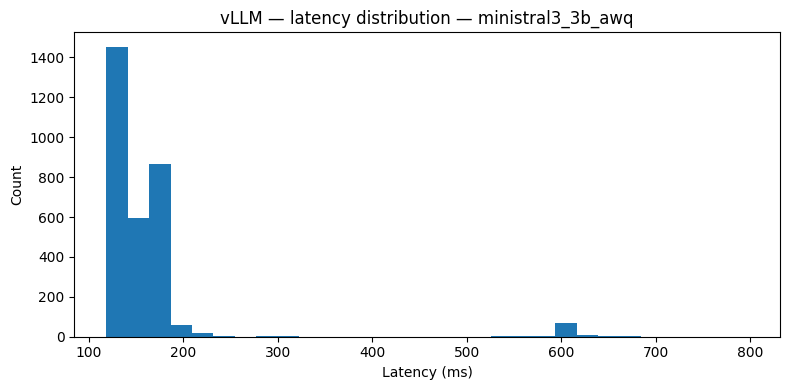

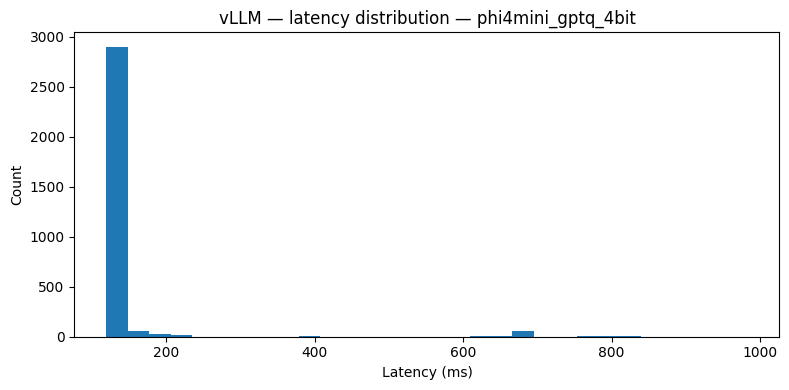

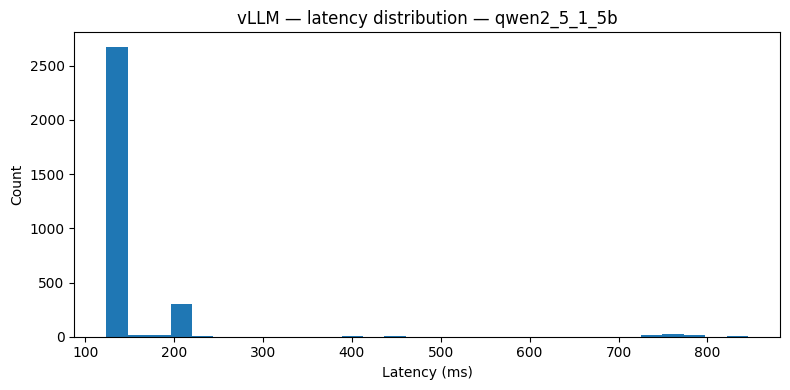

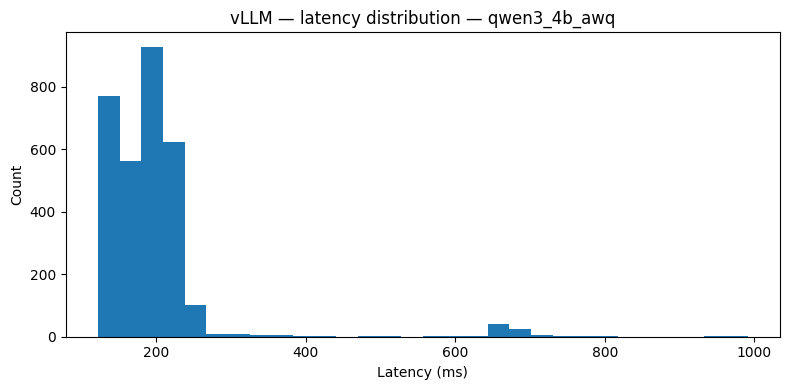

In [100]:
if "latency_ms" in samples.columns:
    for model_name in sorted(samples["model"].dropna().unique()):
        sub = samples[samples["model"] == model_name]["latency_ms"].dropna()

        plt.figure(figsize=(8, 4))
        plt.hist(sub, bins=30)
        plt.xlabel("Latency (ms)")
        plt.ylabel("Count")
        plt.title(f"vLLM — latency distribution — {model_name}")
        plt.tight_layout()
        safe_name = str(model_name).replace("/", "_")
        plt.savefig(FIGURES_DIR / f"latency_distribution_{safe_name}.png", dpi=200)
        plt.show()


 Sample tokens/sec distribution by model

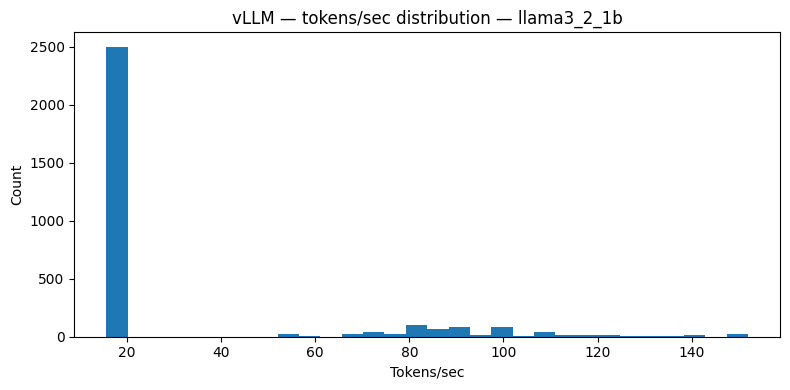

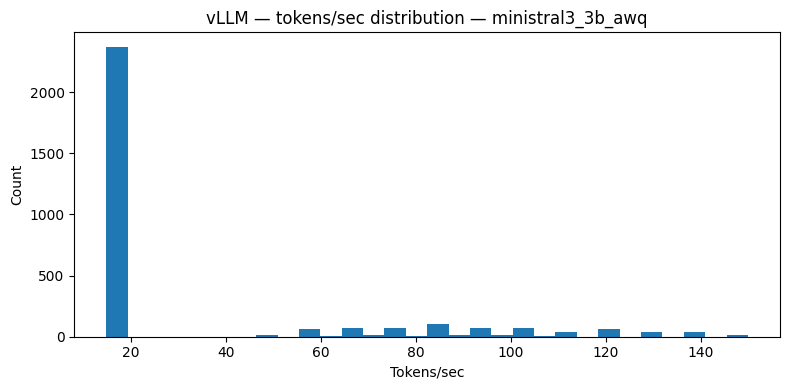

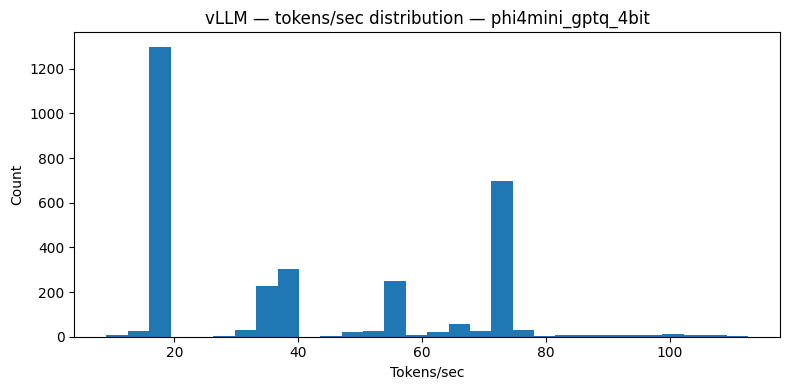

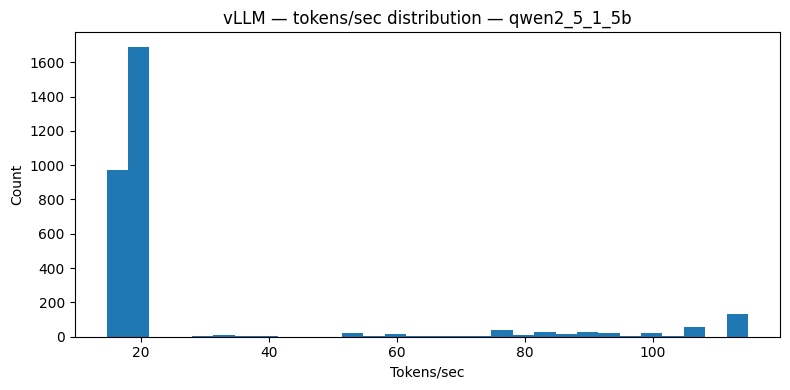

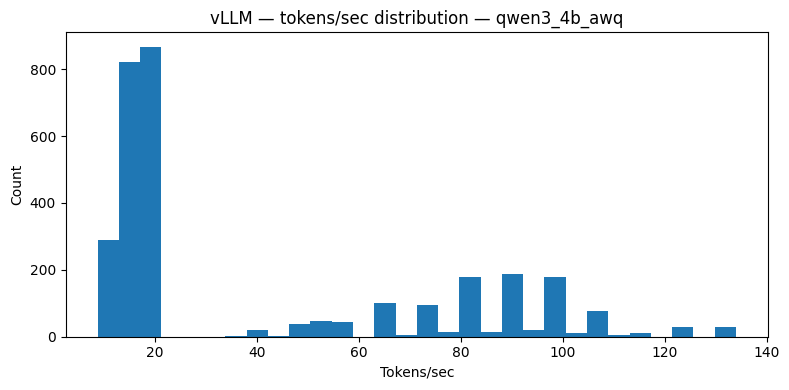

In [101]:
if "tokens_per_sec" in samples.columns:
    for model_name in sorted(samples["model"].dropna().unique()):
        sub = samples[samples["model"] == model_name]["tokens_per_sec"].dropna()

        plt.figure(figsize=(8, 4))
        plt.hist(sub, bins=30)
        plt.xlabel("Tokens/sec")
        plt.ylabel("Count")
        plt.title(f"vLLM — tokens/sec distribution — {model_name}")
        plt.tight_layout()
        safe_name = str(model_name).replace("/", "_")
        plt.savefig(FIGURES_DIR / f"tps_distribution_{safe_name}.png", dpi=200)
        plt.show()


 Sample power distribution by model

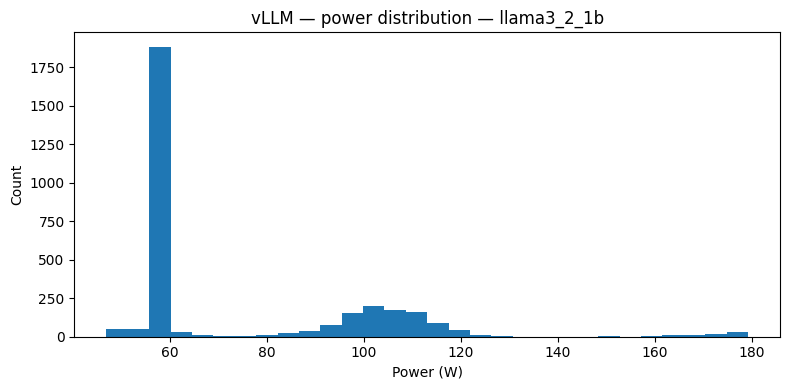

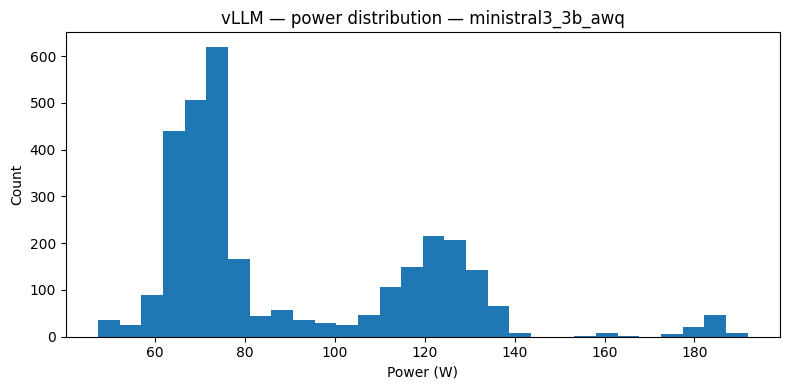

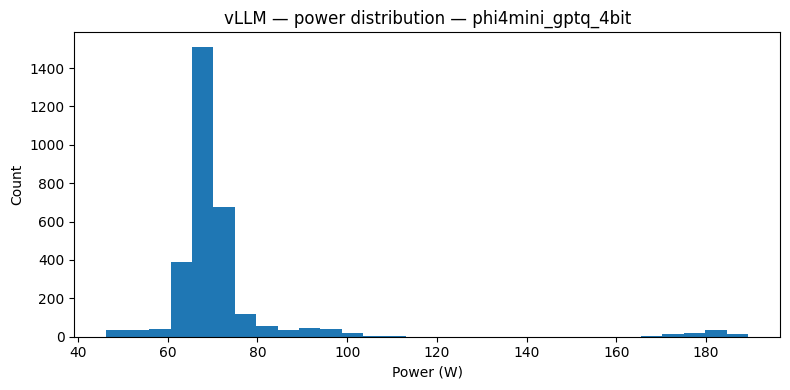

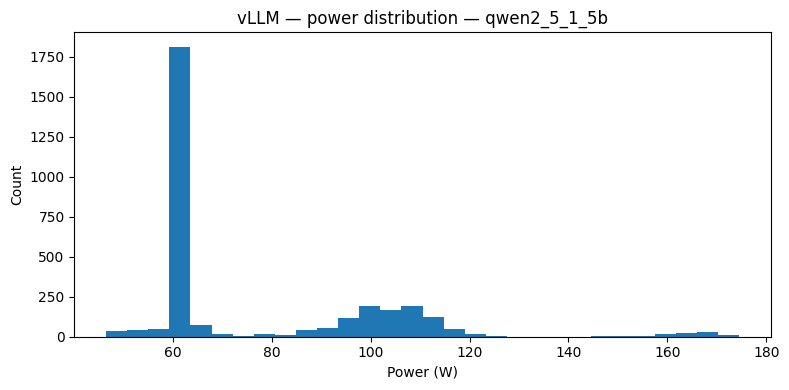

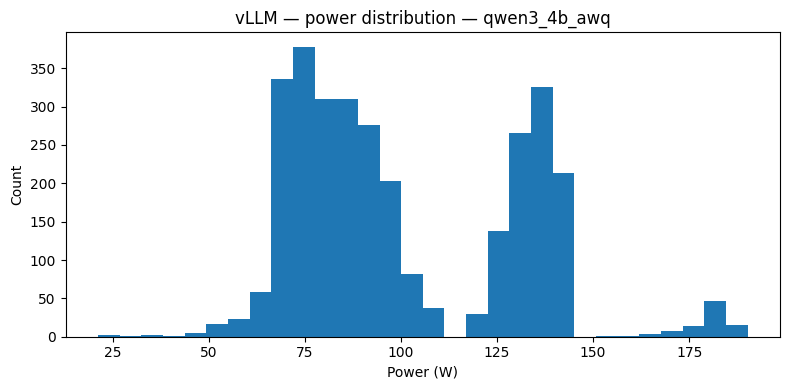

In [102]:
if "power_w_avg" in samples.columns:
    for model_name in sorted(samples["model"].dropna().unique()):
        sub = samples[samples["model"] == model_name]["power_w_avg"].dropna()

        plt.figure(figsize=(8, 4))
        plt.hist(sub, bins=30)
        plt.xlabel("Power (W)")
        plt.ylabel("Count")
        plt.title(f"vLLM — power distribution — {model_name}")
        plt.tight_layout()
        safe_name = str(model_name).replace("/", "_")
        plt.savefig(FIGURES_DIR / f"power_distribution_{safe_name}.png", dpi=200)
        plt.show()


 Ranking previews

In [103]:
display(ranking_accuracy)
display(ranking_efficiency)


,backend,model,n_runs,n_datasets,avg_accuracy,avg_ttft_ms,avg_latency_ms,avg_tps,avg_sustained_tps,avg_cpu,avg_ram_mb,avg_gpu,avg_vram_mb,avg_power_w,avg_tps_per_vram,avg_tps_per_watt,avg_accuracy_per_latency,avg_accuracy_per_vram,avg_accuracy_per_watt
0,vllm,qwen3_4b_awq,1,3,0.478000,99.074733,182.429967,39.535233,15.010633,6.025633,848.470000,32.574467,5283.000000,98.690900,0.007520,0.351571,0.002791,0.000090,0.005783
1,vllm,phi4mini_gptq_4bit,1,3,0.420000,72.685767,128.036433,39.943633,12.119133,6.530667,1069.146667,14.282533,5929.333333,69.607567,0.006734,0.566577,0.003269,0.000071,0.005978
2,vllm,ministral3_3b_awq,1,3,0.380000,82.970433,148.970300,33.962533,13.812333,6.365133,908.360000,34.762467,5231.666667,87.474600,0.006544,0.351647,0.002648,0.000072,0.005291
3,vllm,qwen2_5_1_5b,1,3,0.266667,73.553633,137.434067,26.539100,10.924767,6.679633,821.740000,19.106767,5408.333333,74.374267,0.004908,0.341456,0.002061,0.000049,0.004319
4,vllm,llama3_2_1b,1,3,0.246667,67.851067,127.813933,30.272567,11.680833,6.266567,898.283333,18.261133,5402.000000,73.187233,0.005617,0.385404,0.001994,0.000046,0.004089


,backend,model,n_runs,n_datasets,avg_accuracy,avg_ttft_ms,avg_latency_ms,avg_tps,avg_sustained_tps,avg_cpu,avg_ram_mb,avg_gpu,avg_vram_mb,avg_power_w,avg_tps_per_vram,avg_tps_per_watt,avg_accuracy_per_latency,avg_accuracy_per_vram,avg_accuracy_per_watt
0,vllm,phi4mini_gptq_4bit,1,3,0.420000,72.685767,128.036433,39.943633,12.119133,6.530667,1069.146667,14.282533,5929.333333,69.607567,0.006734,0.566577,0.003269,0.000071,0.005978
1,vllm,llama3_2_1b,1,3,0.246667,67.851067,127.813933,30.272567,11.680833,6.266567,898.283333,18.261133,5402.000000,73.187233,0.005617,0.385404,0.001994,0.000046,0.004089
2,vllm,ministral3_3b_awq,1,3,0.380000,82.970433,148.970300,33.962533,13.812333,6.365133,908.360000,34.762467,5231.666667,87.474600,0.006544,0.351647,0.002648,0.000072,0.005291
3,vllm,qwen3_4b_awq,1,3,0.478000,99.074733,182.429967,39.535233,15.010633,6.025633,848.470000,32.574467,5283.000000,98.690900,0.007520,0.351571,0.002791,0.000090,0.005783
4,vllm,qwen2_5_1_5b,1,3,0.266667,73.553633,137.434067,26.539100,10.924767,6.679633,821.740000,19.106767,5408.333333,74.374267,0.004908,0.341456,0.002061,0.000049,0.004319


 Top-ranked models by accuracy

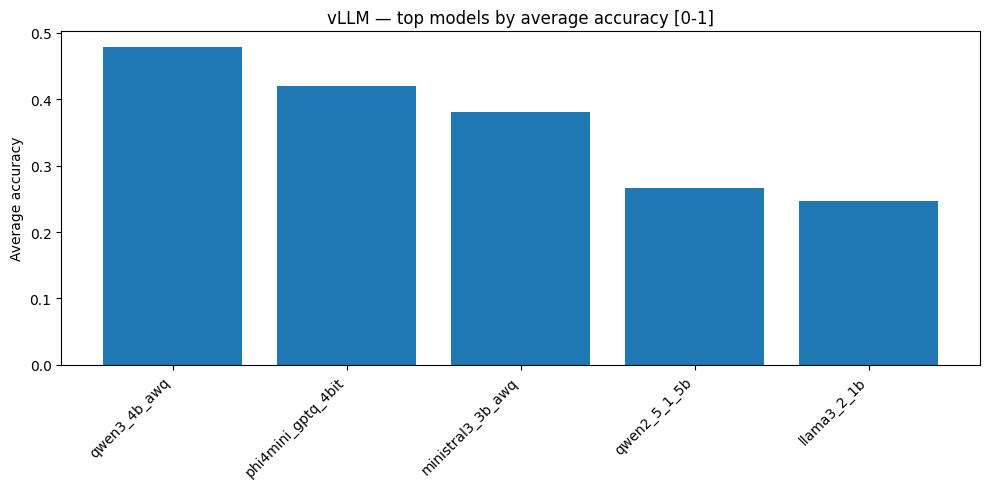

In [104]:
top_acc = ranking_accuracy.head(10).copy()

plt.figure(figsize=(10, 5))
plt.bar(top_acc["model"], top_acc["avg_accuracy"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Average accuracy")
plt.title("vLLM — top models by average accuracy [0-1]")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_ranked_models_accuracy.png", dpi=200)
plt.show()


 Top-ranked models by throughput efficiency

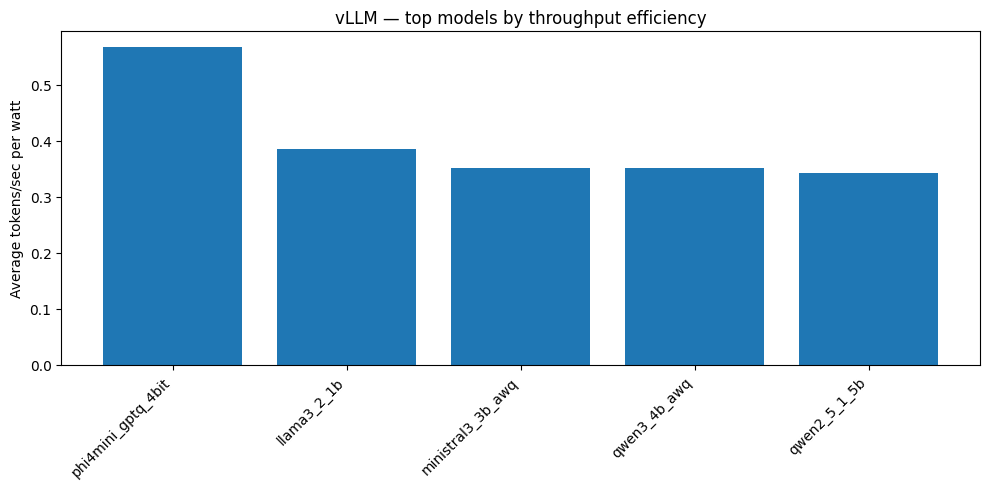

In [105]:
top_eff = ranking_efficiency.head(10).copy()

plt.figure(figsize=(10, 5))
plt.bar(top_eff["model"], top_eff["avg_tps_per_watt"])
plt.xticks(rotation=45, ha="right")
plt.ylabel("Average tokens/sec per watt")
plt.title("vLLM — top models by throughput efficiency")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "top_ranked_models_efficiency.png", dpi=200)
plt.show()


 Saved figures

In [106]:
print("Figures saved in:", FIGURES_DIR)
for p in sorted(FIGURES_DIR.glob("*.png")):
    print("-", p.name)

Figures saved in: /home/stephane/resource-efficiency-benchmark/docs/figures/vllm
- accuracy_by_model.png
- accuracy_vs_latency.png
- accuracy_vs_power.png
- accuracy_vs_vram.png
- box_accuracy_by_model.png
- box_dolly_latency_by_model.png
- box_dolly_throughput_samples.png
- box_gpu_by_model.png
- box_gsm8k_accuracy_by_model.png
- box_gsm8k_latency_by_model.png
- box_hellaswag_accuracy_by_model.png
- box_hellaswag_latency_by_model.png
- box_latency_by_model_sorted.png
- box_mmlu_accuracy_by_model.png
- box_mmlu_latency_by_model.png
- box_power_by_model.png
- box_throughput_by_model.png
- box_tps_per_watt_by_model.png
- box_vram_by_model.png
- dolly_latency_by_model.png
- dolly_throughput_by_model.png
- gpu_by_model.png
- gsm8k_accuracy_by_model.png
- gsm8k_latency_by_model.png
- hellaswag_accuracy_by_model.png
- hellaswag_latency_by_model.png
- latency_by_model.png
- latency_distribution_gemma3_4b_w4a16.png
- latency_distribution_granite4_htiny_awq.png
- latency_distribution_llama3_2_1